**Головских А.В. Проект Билетная площадка**

In [1]:
!pip install sqlalchemy
!pip install psycopg2-binary

In [2]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from sqlalchemy import create_engine

In [3]:
db_config = {'user': 'praktikum_student', # имя пользователя
             'pwd': 'Sdf4$2;d-d30pp', # пароль
             'host': 'rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net',
             'port': 6432, # порт подключения
             'db': 'data-analyst-afisha' # название базы данных
             }

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

engine = create_engine(connection_string)

In [4]:
query = '''
SELECT p.user_id,
       p.device_type_canonical,
       p.order_id,
       p.created_dt_msk AS order_dt,
       p.created_ts_msk AS order_ts,
       p.currency_code,
       p.revenue,
       p.tickets_count,
       p.created_dt_msk::date
         - LAG(p.created_dt_msk::date) OVER (PARTITION BY p.user_id
                                             ORDER BY p.created_dt_msk) AS days_since_prev,
       p.event_id,
       e.event_name_code AS event_name,
       e.event_type_main,
       p.service_name,
       r.region_name,
       c.city_name
FROM afisha.purchases p
INNER JOIN afisha.events  e ON p.event_id  = e.event_id
INNER JOIN afisha.city    c ON e.city_id   = c.city_id
INNER JOIN afisha.regions r ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
  AND e.event_type_main != 'фильм'
ORDER BY p.user_id
'''

df = pd.read_sql_query(query, con=engine)
df

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290606,fffcd3dde79eb2c,mobile,368591,2024-10-27,2024-10-27 17:54:52,rub,965.57,4,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск
290607,fffcd3dde79eb2c,mobile,368562,2024-10-27,2024-10-27 17:53:53,rub,1448.36,6,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск
290608,fffcd3dde79eb2c,desktop,8473772,2024-10-30,2024-10-30 13:37:43,rub,178.95,2,3.0,205231,74883818-57a6-494a-b162-bb0260877cbf,театр,Прачечная,Каменевский регион,Глиногорск
290609,fffeeb3c120cf0b,desktop,5526067,2024-09-24,2024-09-24 10:07:42,rub,661.53,2,NaN,454526,6f4c6a50-0106-407b-8f54-332c740b01da,стендап,Билеты без проблем,Широковская область,Ягодиновка


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [6]:
# пропуски по столбцам
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
dtype: int64

In [7]:
# период данных и количество пользователей
print('Период:', df['order_dt'].min(), '—', df['order_dt'].max())
print('Заказов:', df['order_id'].nunique())
print('Пользователей:', df['user_id'].nunique())

Период: 2024-06-01 00:00:00 — 2024-10-31 00:00:00
Заказов: 290611
Пользователей: 21933


**Промежуточный вывод**

Выгружено 290 611 строк и 15 столбцов. Каждая строка - отдельный заказ (все 290 611 `order_id` уникальны). Заказы совершили 21 933 пользователя. Данные охватывают период с 1 июня по 31 октября 2024 года. В выгрузку вошли только заказы с мобильных и десктопных устройств, заказы на фильмы исключены.

Особенности данных:
- Пропуски есть только в `days_since_prev` (21 933 значения). Их число совпадает с числом пользователей, то есть пропуск стоит у первой покупки каждого пользователя. Это ожидаемо, и заполнять эти пропуски не нужно.
- Типы данных в целом корректны: `order_dt` и `order_ts` уже имеют тип `datetime64`. `days_since_prev` имеет тип `float64` из-за пропусков, поэтому его можно привести к `Int64`.
- Выручка представлена в двух валютах — рублях и тенге, её нужно привести к рублям.



In [8]:
# загружаем курс тенге: curs — стоимость 100 тенге в рублях
tenge = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
tenge['data'] = pd.to_datetime(tenge['data'])
tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [9]:
# присоединяем курс по дате заказа
df = df.merge(tenge[['data', 'curs']], left_on='order_dt', right_on='data', how='left')

# переводим тенге в рубли, курс указан за 100 тенге
df['revenue_rub'] = df['revenue']
kzt = df['currency_code'] == 'kzt'
df.loc[kzt, 'revenue_rub'] = df.loc[kzt, 'revenue'] * df.loc[kzt, 'curs'] / 100

# удаляем вспомогательные столбцы
df = df.drop(columns=['data', 'curs'])

df.loc[kzt, ['order_dt', 'currency_code', 'revenue', 'revenue_rub']].head()

,order_dt,currency_code,revenue,revenue_rub
70,2024-09-17,kzt,518.10,98.503762
89,2024-09-02,kzt,347.18,65.731589
96,2024-09-09,kzt,328.77,61.148261
277,2024-06-11,kzt,22021.55,4380.702898
460,2024-06-04,kzt,7397.66,1478.296591


In [10]:
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

In [11]:
# сокращаем размерность числовых столбцов
df['order_id'] = pd.to_numeric(df['order_id'], downcast='integer')
df['event_id'] = pd.to_numeric(df['event_id'], downcast='integer')
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['revenue'] = pd.to_numeric(df['revenue'], downcast='float')
df['revenue_rub'] = pd.to_numeric(df['revenue_rub'], downcast='float')
df['days_since_prev'] = df['days_since_prev'].astype('Int16')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int32         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  Int16         
 9   event_id               290611 non-null  int32         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [12]:
for col in ['device_type_canonical', 'currency_code', 'event_type_main',
            'service_name', 'region_name', 'city_name']:
    print(col)
    print(df[col].value_counts(), '\n')

device_type_canonical
device_type_canonical
mobile     232490
desktop     58121
Name: count, dtype: int64 

currency_code
currency_code
rub    285542
kzt      5069
Name: count, dtype: int64 

event_type_main
event_type_main
концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: count, dtype: int64 

service_name
service_name
Билеты без проблем        63519
Лови билет!               41124
Билеты в руки             40343
Мой билет                 34839
Облачко                   26642
Лучшие билеты             17774
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка    

In [13]:
# количество уникальных значений до и после нормализации (регистр, пробелы)
for col in ['event_type_main', 'service_name', 'region_name', 'city_name']:
    print(col, df[col].nunique(), df[col].str.strip().str.lower().nunique())

event_type_main 7 7
service_name 36 36
region_name 81 81
city_name 352 352


In [14]:
print('Полных дубликатов:', df.duplicated().sum())
print('Дубликатов order_id:', df['order_id'].duplicated().sum())

Полных дубликатов: 0
Дубликатов order_id: 0


In [15]:
df[['revenue_rub', 'tickets_count']].describe()

,revenue_rub,tickets_count
count,290611.000000,290611.000000
mean,555.571987,2.754311
std,875.498172,1.170620
min,-90.760000,1.000000
25%,113.970000,2.000000
50%,351.140000,3.000000
75%,802.050000,4.000000
max,81174.540000,57.000000


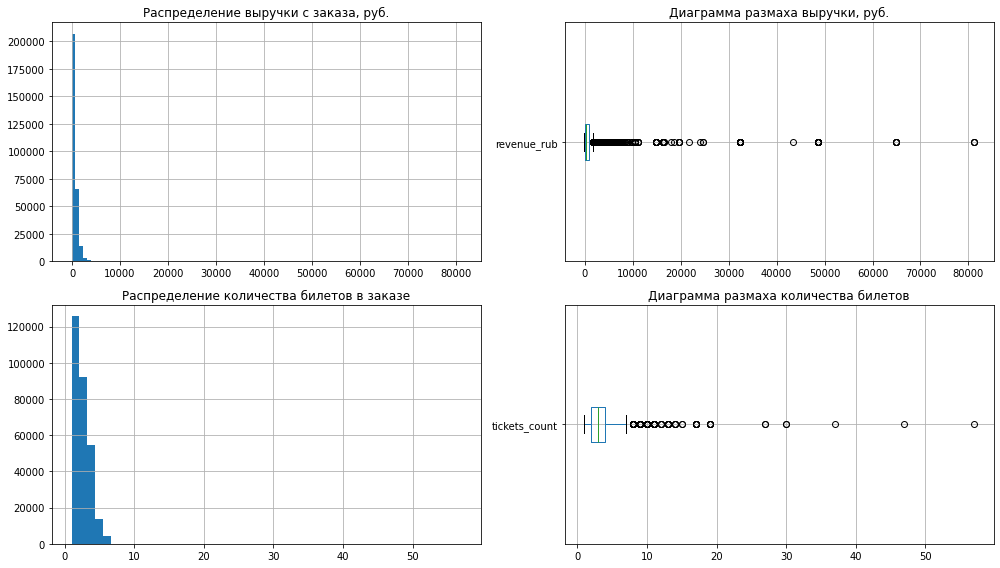

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

df['revenue_rub'].hist(bins=100, ax=axes[0, 0])
axes[0, 0].set_title('Распределение выручки с заказа, руб.')

df.boxplot(column='revenue_rub', ax=axes[0, 1], vert=False)
axes[0, 1].set_title('Диаграмма размаха выручки, руб.')

df['tickets_count'].hist(bins=50, ax=axes[1, 0])
axes[1, 0].set_title('Распределение количества билетов в заказе')

df.boxplot(column='tickets_count', ax=axes[1, 1], vert=False)
axes[1, 1].set_title('Диаграмма размаха количества билетов')

plt.tight_layout()
plt.show()

In [17]:
rows_before = df.shape[0]

p99 = df['revenue_rub'].quantile(0.99)
print('99-й перцентиль выручки:', round(p99, 2))

df = df[df['revenue_rub'] <= p99]

rows_after = df.shape[0]
print('Строк до:', rows_before)
print('Строк после:', rows_after)
print('Удалено:', rows_before - rows_after, f'({(rows_before - rows_after) / rows_before:.2%})')

99-й перцентиль выручки: 2628.42
Строк до: 290611
Строк после: 287786
Удалено: 2825 (0.97%)


**Промежуточный вывод**

Выполненная предобработка:

- **Приведение выручки к рублям.** Заказы в тенге (5 069 заказов, около 1,7%) пересчитаны в рубли по курсу на дату заказа из датасета `final_tickets_tenge_df.csv` (курс указан за 100 тенге). Создан новый столбец `revenue_rub` — выручка с заказа в российских рублях. Курс найден для всех дат, пропусков в `revenue_rub` нет.
- **Пропуски.** Есть только в `days_since_prev` (21 933 значения, по числу пользователей). Это первые покупки пользователей, поэтому пропуски не заполняем.
- **Типы данных.** `order_dt` и `order_ts` уже имели тип `datetime64`. Размерность числовых столбцов сокращена: `order_id` и `event_id` — `int32`, `tickets_count` — `int8`, `revenue` и `revenue_rub` — `float32`, `days_since_prev` — `Int16` (целочисленный тип с поддержкой пропусков). Объём памяти уменьшился с 33,3 до 29,9 МБ.
- **Категориальные данные.** Ошибок в написании и неявных дубликатов не обнаружено: число уникальных значений до и после приведения к нижнему регистру и удаления пробелов совпадает. В `event_type_main` есть категория «другое» (65 867 заказов, около 23%), которая означает отсутствие точной информации о типе мероприятия. Из-за большой доли она оставлена как отдельная категория. У части билетных операторов, регионов и городов очень мало заказов (вплоть до 1), выводы по таким категориям ненадёжны.
- **Дубликаты.** Полных дубликатов и повторов `order_id` нет.
- **Выручка `revenue_rub`.** Распределение сильно скошено вправо: медиана 351 руб., среднее 556 руб., при этом максимум 81 175 руб. — явные выбросы. Также встречаются отрицательные значения (минимум −90,76 руб.), вероятно, возвраты. Данные отфильтрованы по 99-му перцентилю (2 628,42 руб.).
- **Количество билетов `tickets_count`.** Обычно в заказе от 2 до 4 билетов (медиана 3), но встречаются заказы до 57 билетов. Это редкие крупные заказы.

**Объём отфильтрованных данных.** После фильтрации по 99-му перцентилю выручки осталось 287 786 строк из 290 611. Удалено 2 825 строк (0,97%). Это небольшая доля, которая не повлияет существенно на результаты анализа.

**Задача 3.1**

In [18]:
# сортируем заказы по времени, чтобы first/last брали первый и последний заказ
df = df.sort_values('order_ts')

user_profile = df.groupby('user_id').agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_service=('service_name', 'first'),
    first_event_type=('event_type_main', 'first'),
    orders_count=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets=('tickets_count', 'mean'),
    avg_days_between=('days_since_prev', 'mean')
).reset_index()

# бинарные признаки
user_profile['is_two'] = (user_profile['orders_count'] >= 2).astype(int)
user_profile['is_five'] = (user_profile['orders_count'] >= 5).astype(int)

user_profile.head()

,user_id,first_order_dt,last_order_dt,first_device,first_region,first_service,first_event_type,orders_count,avg_revenue_rub,avg_tickets,avg_days_between,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,<NA>,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,75.0,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,51.0,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,<NA>,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,16.0,1,0


In [19]:
user_profile['avg_days_between'] = user_profile['avg_days_between'].to_numpy(dtype='float64', na_value=np.nan)

**Задача 3.2**

In [20]:
print('Всего пользователей:', user_profile['user_id'].nunique())
print('Средняя выручка с одного заказа, руб.:', round(df['revenue_rub'].mean(), 2))
print('Доля пользователей с 2 и более заказами:', f"{user_profile['is_two'].mean():.2%}")
print('Доля пользователей с 5 и более заказами:', f"{user_profile['is_five'].mean():.2%}")

Всего пользователей: 21854
Средняя выручка с одного заказа, руб.: 518.03
Доля пользователей с 2 и более заказами: 61.71%
Доля пользователей с 5 и более заказами: 29.01%


In [21]:
user_profile[['orders_count', 'avg_tickets', 'avg_days_between']].describe()

,orders_count,avg_tickets,avg_days_between
count,21854.000000,21854.000000,13521.000000
mean,13.168573,2.743129,15.836109
std,121.674800,0.913080,22.297926
min,1.000000,1.000000,0.000000
25%,1.000000,2.000000,1.000000
50%,2.000000,2.750000,8.000000
75%,5.000000,3.076923,20.400000
max,10181.000000,11.000000,148.000000


In [22]:
# смотрим хвосты распределения
user_profile[['orders_count', 'avg_tickets']].quantile([0.90, 0.95, 0.99])

,orders_count,avg_tickets
0.90,15.00,4.0
0.95,31.35,4.0
0.99,152.00,5.0


In [23]:
users_before = user_profile.shape[0]

p99_orders = user_profile['orders_count'].quantile(0.99)
print('99-й перцентиль числа заказов:', p99_orders)

user_profile = user_profile[user_profile['orders_count'] <= p99_orders]

users_after = user_profile.shape[0]
print('Пользователей до:', users_before)
print('Пользователей после:', users_after)
print('Удалено:', users_before - users_after, f'({(users_before - users_after) / users_before:.2%})')

99-й перцентиль числа заказов: 152.0
Пользователей до: 21854
Пользователей после: 21638
Удалено: 216 (0.99%)


In [24]:
# статистика по обновлённому датасету
print('Всего пользователей:', user_profile.shape[0])
print('Доля пользователей с 2 и более заказами:', f"{user_profile['is_two'].mean():.2%}")
print('Доля пользователей с 5 и более заказами:', f"{user_profile['is_five'].mean():.2%}")
user_profile[['orders_count', 'avg_tickets', 'avg_days_between']].describe()

Всего пользователей: 21638
Доля пользователей с 2 и более заказами: 61.33%
Доля пользователей с 5 и более заказами: 28.30%


,orders_count,avg_tickets,avg_days_between
count,21638.000000,21638.000000,13305.000000
mean,6.501294,2.743319,16.085749
std,14.324031,0.917486,22.391232
min,1.000000,1.000000,0.000000
25%,1.000000,2.000000,1.333333
50%,2.000000,2.750000,8.333333
75%,5.000000,3.095238,20.750000
max,152.000000,11.000000,148.000000


**Промежуточный вывод**

Для каждого пользователя построен профиль со следующими признаками:
- `first_order_dt`, `last_order_dt` — даты первого и последнего заказа;
- `first_device` — устройство первого заказа;
- `first_region` — регион первого заказа;
- `first_service` — билетный оператор первого заказа;
- `first_event_type` — тип мероприятия первого заказа;
- `orders_count` — общее число заказов;
- `avg_revenue_rub` — средняя выручка с заказа, руб.;
- `avg_tickets` — среднее число билетов в заказе;
- `avg_days_between` — среднее число дней между заказами (у пользователей с одним заказом — пропуск);
- `is_two`, `is_five` — бинарные признаки «2 и более заказа» и «5 и более заказов».

**Оценка данных**

В выборке 21 854 пользователя. Средняя выручка с заказа — 518,02 руб. Повторный заказ совершили 61,71% пользователей, 5 и более заказов — 29,01%. Объём данных достаточен для анализа.

- **Число заказов (`orders_count`).** Медиана — 2 заказа, 75% пользователей сделали не более 5 заказов, 95% — не более 31. При этом максимум — 10 181 заказ, а среднее (13,2) сильно завышено хвостом распределения. Сотни и тысячи заказов за 5 месяцев нехарактерны для обычного пользователя. Скорее всего, это перекупщики, корпоративные клиенты или технические аккаунты. Такие значения искажают статистику и не отражают поведение типичных покупателей.
- **Среднее число билетов (`avg_tickets`).** Медиана — 2,75, 99% пользователей покупают в среднем не более 5 билетов, максимум — 11. Распределение без сильных аномалий, значения правдоподобны: это может быть покупка на компанию или семью. Данные оставлены без изменений.
- **Среднее число дней между покупками (`avg_days_between`).** Медиана — 8 дней, максимум — 148, что укладывается в период данных (5 месяцев). Аномалий нет.

**Фильтрация**

Пользователи с аномально большим числом заказов отфильтрованы по 99-му перцентилю (152 заказа). Удалено 216 пользователей (0,99%), осталось 21 638.

Статистика после фильтрации:
- Среднее число заказов снизилось с 13,2 до 6,5, стандартное отклонение — с 121,7 до 14,3. Медиана не изменилась и составляет 2 заказа.
- Доля пользователей с 2 и более заказами — 61,33%, с 5 и более — 28,30%.
- Показатели по билетам и интервалам между покупками практически не изменились.

Фильтрация убрала экстремальные значения и почти не повлияла на долю возвращающихся пользователей.

**4.1.1. Распределение пользователей по сегментам**

In [25]:
def segment_share(col):
    result = (user_profile.groupby(col)['user_id'].count()
              .rename('users')
              .sort_values(ascending=False)
              .to_frame())
    result['share'] = (result['users'] / result['users'].sum()).round(4)
    return result

for col in ['first_event_type', 'first_device', 'first_region', 'first_service']:
    print(col)
    display(segment_share(col).head(15))

first_event_type


,users,share
first_event_type,,
концерты,9560,0.4418
другое,5426,0.2508
театр,4239,0.1959
стендап,1110,0.0513
спорт,794,0.0367
выставки,414,0.0191
ёлки,95,0.0044


first_device


,users,share
first_device,,
mobile,17924,0.8284
desktop,3714,0.1716


first_region


,users,share
first_region,,
Каменевский регион,7085,0.3274
Североярская область,3767,0.1741
Широковская область,1224,0.0566
Озернинский край,675,0.0312
Малиновоярский округ,525,0.0243
Шанырский регион,500,0.0231
Травяная область,488,0.0226
Светополянский округ,457,0.0211
Речиновская область,440,0.0203


first_service


,users,share
first_service,,
Билеты без проблем,5186,0.2397
Мой билет,2969,0.1372
Лови билет!,2809,0.1298
Билеты в руки,2559,0.1183
Облачко,2177,0.1006
Весь в билетах,1285,0.0594
Лучшие билеты,1184,0.0547
Прачечная,583,0.0269
Край билетов,454,0.0210


**4.1.2. Доля вернувшихся пользователей по сегментам**

Доля вернувшихся в среднем по выборке: 61.33%


,users,return_rate
first_event_type,,
ёлки,95,0.557895
спорт,794,0.557935
другое,5426,0.596203
стендап,1110,0.609009
концерты,9560,0.618305
театр,4239,0.633876
выставки,414,0.640097


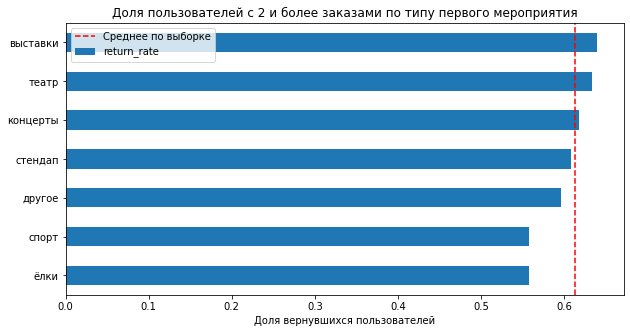

,users,return_rate
first_device,,
mobile,17924,0.608123
desktop,3714,0.638126


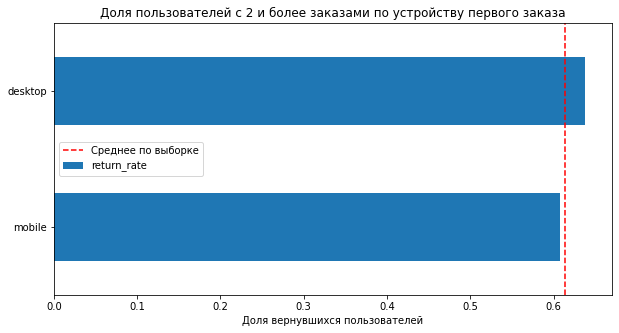

,users,return_rate
first_region,,
Озернинский край,675,0.552593
Малиновоярский округ,525,0.560000
Яблоневская область,411,0.593674
Травяная область,488,0.614754
Каменевский регион,7085,0.623994
Речиновская область,440,0.634091
Североярская область,3767,0.638174
Широковская область,1224,0.645425
Светополянский округ,457,0.656455


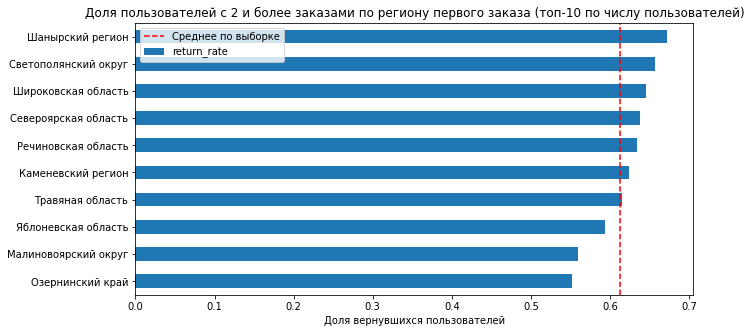

,users,return_rate
first_service,,
Билеты без проблем,5186,0.604126
Мой билет,2969,0.608622
Лови билет!,2809,0.609114
Лучшие билеты,1184,0.612331
Облачко,2177,0.612770
Прачечная,583,0.626072
Билеты в руки,2559,0.627198
Весь в билетах,1285,0.628794
Дом культуры,356,0.646067


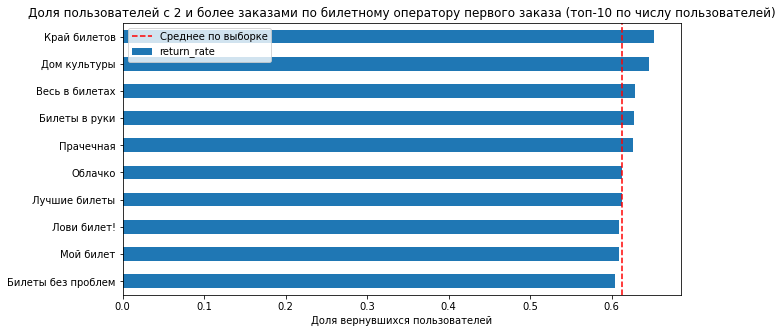

In [26]:
avg_return = user_profile['is_two'].mean()
print('Доля вернувшихся в среднем по выборке:', f'{avg_return:.2%}')

def return_rate(col, top=None):
    result = (user_profile.groupby(col)
              .agg(users=('user_id', 'count'), return_rate=('is_two', 'mean'))
              .sort_values('users', ascending=False))
    if top:
        result = result.head(top)
    return result

titles = {'first_event_type': 'типу первого мероприятия',
          'first_device': 'устройству первого заказа',
          'first_region': 'региону первого заказа (топ-10 по числу пользователей)',
          'first_service': 'билетному оператору первого заказа (топ-10 по числу пользователей)'}

for col, title in titles.items():
    top = 10 if col in ['first_region', 'first_service'] else None
    data = return_rate(col, top).sort_values('return_rate')
    display(data)

    ax = data['return_rate'].plot(kind='barh', figsize=(10, 5))
    ax.axvline(avg_return, color='red', linestyle='--', label='Среднее по выборке')
    ax.set_title(f'Доля пользователей с 2 и более заказами по {title}')
    ax.set_xlabel('Доля вернувшихся пользователей')
    ax.set_ylabel('')
    ax.legend()
    plt.show()

**4.1.3. Проверка гипотез**

In [27]:
# Гипотеза 1: спорт vs концерты
display(user_profile[user_profile['first_event_type'].isin(['спорт', 'концерты'])]
        .groupby('first_event_type')
        .agg(users=('user_id', 'count'), return_rate=('is_two', 'mean')))

,users,return_rate
first_event_type,,
концерты,9560,0.618305
спорт,794,0.557935


In [28]:
# Гипотеза 2: топ-10 регионов по числу пользователей vs остальные
top_regions = user_profile['first_region'].value_counts().head(10).index

user_profile['region_group'] = np.where(user_profile['first_region'].isin(top_regions),
                                        'топ-10 регионов', 'остальные регионы')

display(user_profile.groupby('region_group')
        .agg(users=('user_id', 'count'), return_rate=('is_two', 'mean')))

,users,return_rate
region_group,,
остальные регионы,6066,0.581767
топ-10 регионов,15572,0.625546


**4.2.1. Средняя выручка: один заказ vs 2 и более**

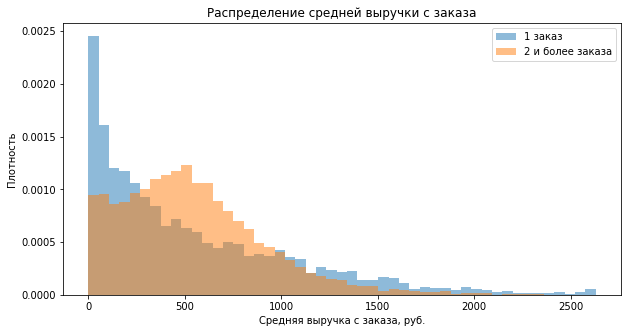

,count,mean,std,min,25%,50%,75%,max
is_two,,,,,,,,
0,8368.0,545.295642,519.514097,-10.770,132.070000,378.030000,830.3175,2628.421739
1,13270.0,544.337170,369.354468,-5.385,270.814375,495.772429,745.1655,2628.421739


In [29]:
bins = np.linspace(0, user_profile['avg_revenue_rub'].max(), 50)

plt.figure(figsize=(10, 5))
plt.hist(user_profile[user_profile['orders_count'] == 1]['avg_revenue_rub'],
         bins=bins, alpha=0.5, density=True, label='1 заказ')
plt.hist(user_profile[user_profile['orders_count'] >= 2]['avg_revenue_rub'],
         bins=bins, alpha=0.5, density=True, label='2 и более заказа')
plt.title('Распределение средней выручки с заказа')
plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность')
plt.legend()
plt.show()

display(user_profile.groupby('is_two')['avg_revenue_rub'].describe())

**4.2.2. Средняя выручка: 2–4 заказа vs 5 и более**

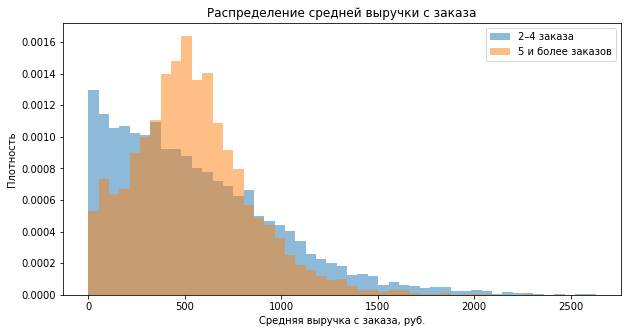

2–4 заказа:
 count    7147.000000
mean      551.572386
std       420.197691
min        -5.385000
25%       218.428750
50%       471.266667
75%       798.550000
max      2628.421739
Name: avg_revenue_rub, dtype: float64 

5 и более заказов:
 count    6123.000000
mean      535.891950
std       299.089582
min         0.000000
25%       330.456122
50%       512.650613
75%       700.809038
max      2299.869022
Name: avg_revenue_rub, dtype: float64


In [30]:
group_2_4 = user_profile[user_profile['orders_count'].between(2, 4)]
group_5 = user_profile[user_profile['orders_count'] >= 5]

plt.figure(figsize=(10, 5))
plt.hist(group_2_4['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='2–4 заказа')
plt.hist(group_5['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='5 и более заказов')
plt.title('Распределение средней выручки с заказа')
plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность')
plt.legend()
plt.show()

print('2–4 заказа:\n', group_2_4['avg_revenue_rub'].describe(), '\n')
print('5 и более заказов:\n', group_5['avg_revenue_rub'].describe())

**4.2.3. Среднее количество билетов в заказе**

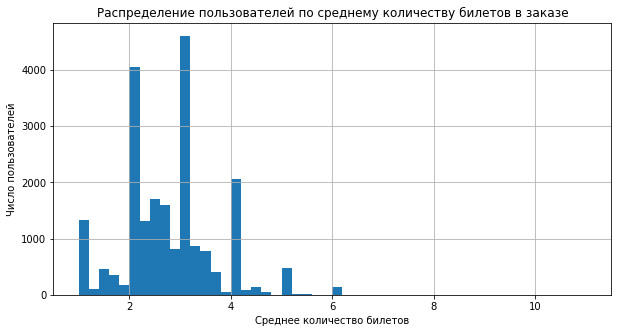

count    21638.000000
mean         2.743319
std          0.917486
min          1.000000
25%          2.000000
50%          2.750000
75%          3.095238
max         11.000000
Name: avg_tickets, dtype: float64


In [31]:
plt.figure(figsize=(10, 5))
user_profile['avg_tickets'].hist(bins=50)
plt.title('Распределение пользователей по среднему количеству билетов в заказе')
plt.xlabel('Среднее количество билетов')
plt.ylabel('Число пользователей')
plt.show()

print(user_profile['avg_tickets'].describe())

,users,return_rate,share_users
tickets_segment,,,
от 1 до 2,2419,0.513022,0.111794
от 2 до 3,9498,0.735839,0.438950
от 3 до 5,9060,0.542605,0.418708
от 5 и более,661,0.187595,0.030548


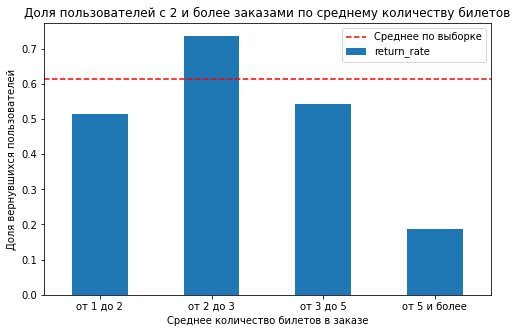

In [32]:
user_profile['tickets_segment'] = pd.cut(user_profile['avg_tickets'],
                                         bins=[1, 2, 3, 5, np.inf],
                                         labels=['от 1 до 2', 'от 2 до 3', 'от 3 до 5', 'от 5 и более'],
                                         right=False)

tickets_seg = (user_profile.groupby('tickets_segment')
               .agg(users=('user_id', 'count'), return_rate=('is_two', 'mean')))
tickets_seg['share_users'] = tickets_seg['users'] / tickets_seg['users'].sum()
display(tickets_seg)

ax = tickets_seg['return_rate'].plot(kind='bar', figsize=(8, 5), rot=0)
ax.axhline(avg_return, color='red', linestyle='--', label='Среднее по выборке')
ax.set_title('Доля пользователей с 2 и более заказами по среднему количеству билетов')
ax.set_xlabel('Среднее количество билетов в заказе')
ax.set_ylabel('Доля вернувшихся пользователей')
ax.legend()
plt.show()

**4.3.1. День недели первой покупки**

,users,return_rate
first_weekday,,
Пн,2930,0.630375
Вт,3176,0.619018
Ср,3057,0.621851
Чт,3113,0.594282
Пт,3259,0.598343
Сб,3326,0.628082
Вс,2777,0.600288


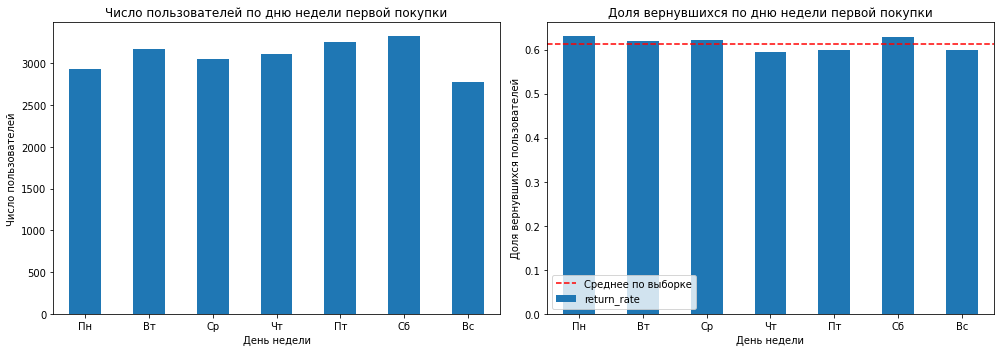

In [33]:
user_profile['first_weekday'] = user_profile['first_order_dt'].dt.dayofweek

weekday_names = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'}

weekday = (user_profile.groupby('first_weekday')
           .agg(users=('user_id', 'count'), return_rate=('is_two', 'mean'))
           .rename(index=weekday_names))
display(weekday)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekday['users'].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Число пользователей по дню недели первой покупки')
axes[0].set_xlabel('День недели')
axes[0].set_ylabel('Число пользователей')

weekday['return_rate'].plot(kind='bar', ax=axes[1], rot=0)
axes[1].axhline(avg_return, color='red', linestyle='--', label='Среднее по выборке')
axes[1].set_title('Доля вернувшихся по дню недели первой покупки')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Доля вернувшихся пользователей')
axes[1].legend()

plt.tight_layout()
plt.show()

**4.3.2. Средний интервал между заказами**

Средний интервал, 2–4 заказа: 21.3 дн.
Средний интервал, 5 и более заказов: 9.9 дн.


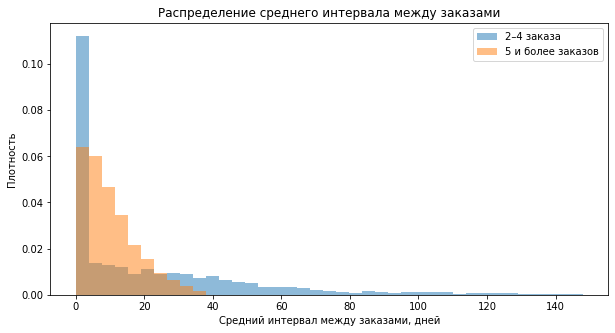

In [34]:
print('Средний интервал, 2–4 заказа:', round(group_2_4['avg_days_between'].mean(), 1), 'дн.')
print('Средний интервал, 5 и более заказов:', round(group_5['avg_days_between'].mean(), 1), 'дн.')

days_bins = np.linspace(0, user_profile['avg_days_between'].max(), 40)

plt.figure(figsize=(10, 5))
plt.hist(group_2_4['avg_days_between'].dropna().astype(float), bins=days_bins,
         alpha=0.5, density=True, label='2–4 заказа')
plt.hist(group_5['avg_days_between'].dropna().astype(float), bins=days_bins,
         alpha=0.5, density=True, label='5 и более заказов')
plt.title('Распределение среднего интервала между заказами')
plt.xlabel('Средний интервал между заказами, дней')
plt.ylabel('Плотность')
plt.legend()
plt.show()

**4.4.1. Корреляционный анализ phi_k**

In [35]:
corr_cols = ['first_device', 'first_region', 'first_service', 'first_event_type',
             'avg_revenue_rub', 'avg_tickets', 'avg_days_between', 'orders_count']

phik_matrix = user_profile[corr_cols].phik_matrix(
    interval_cols=['avg_revenue_rub', 'avg_tickets', 'avg_days_between', 'orders_count'])

display(phik_matrix[['orders_count']].drop('orders_count').sort_values('orders_count', ascending=False))
print(user_profile['orders_count'].value_counts().head(10))

/Users/andreygolova/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/andreygolova/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/andreygolova/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/andreygolova/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2'

,orders_count
avg_days_between,0.283791
avg_tickets,0.225904
avg_revenue_rub,0.219482
first_region,0.113663
first_event_type,0.027745
first_service,0.027483
first_device,0.025945


orders_count
1     8368
2     3572
3     2175
4     1400
5      971
6      700
7      542
8      455
9      384
10     291
Name: count, dtype: int64


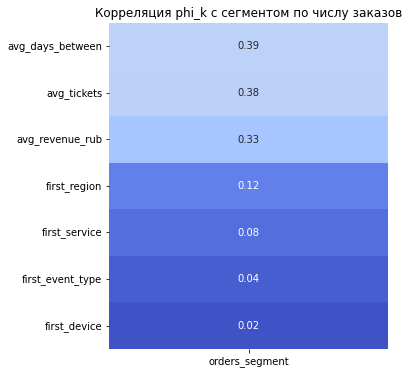

In [36]:
user_profile['orders_segment'] = pd.cut(user_profile['orders_count'],
                                        bins=[0, 1, 4, np.inf],
                                        labels=['1 заказ', '2–4 заказа', '5 и более'])

corr_cols_seg = ['first_device', 'first_region', 'first_service', 'first_event_type',
                 'avg_revenue_rub', 'avg_tickets', 'avg_days_between', 'orders_segment']

phik_matrix_seg = user_profile[corr_cols_seg].phik_matrix(
    interval_cols=['avg_revenue_rub', 'avg_tickets', 'avg_days_between'])

corr_with_orders = (phik_matrix_seg[['orders_segment']]
                    .drop('orders_segment')
                    .sort_values('orders_segment', ascending=False))

plt.figure(figsize=(5, 6))
sns.heatmap(corr_with_orders, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1, cbar=False)
plt.title('Корреляция phi_k с сегментом по числу заказов')
plt.show()

**Вывод по задаче 4.4.1**

Сначала коэффициент phi_k рассчитан между признаками профиля и общим числом заказов (`orders_count`). Наибольшие значения получились у поведенческих признаков: средний интервал между заказами — 0,28, среднее число билетов — 0,23, средняя выручка с заказа — 0,22. Связь слабая. Распределение числа заказов сильно скошено: пользователи с одним заказом составляют около 39% выборки (8 368 из 21 638), а дальше число пользователей быстро убывает. Поэтому анализ повторён на сегментах: «1 заказ», «2–4 заказа», «5 и более».

После разбиения на сегменты связь стала заметнее. С количеством заказов сильнее всего связаны:
- **средний интервал между заказами** (0,39). У пользователей с одним заказом интервала нет, поэтому коэффициент отражает различие между группами «2–4» и «5 и более»;
- **среднее число билетов в заказе** (0,38);
- **средняя выручка с заказа** (0,33).

Это умеренная связь, и все три признака описывают поведение пользователя, а не его первый заказ.

Признаки первого заказа связаны с числом заказов слабо: регион — 0,12, оператор, тип мероприятия и устройство — меньше 0,1, то есть связи практически нет. Значит, по характеристикам первого заказа предсказать, станет ли пользователь постоянным, сложно. Гораздо информативнее то, как пользователь ведёт себя дальше: как часто покупает, сколько билетов берёт и на какую сумму.

**5. Общие выводы и рекомендации**

### Основные результаты

**Выборка и распределение по числу заказов.** В итоговой выборке 21 638 пользователей. Медиана — 2 заказа, среднее — 6,5 (распределение сильно скошено вправо). Один заказ сделали 38,7% пользователей, 2–4 заказа — 33,0%, 5 и более — 28,3%. Таким образом, повторно возвращаются **61,3%** пользователей. Средняя выручка с заказа — 518 руб., в заказе в среднем 2,7 билета, медианный интервал между покупками — 8 дней.

**Признаки первого заказа связаны с возвратом слабо.** Доля вернувшихся в крупных сегментах — от 55% до 67%.
- Тип мероприятия: чаще возвращаются начавшие с театра (63,4%) и выставок (64,0%), реже — со спорта (55,8%) и ёлок (55,8%). Гипотеза о том, что любители спорта возвращаются чаще любителей концертов, **не подтвердилась**: 55,8% против 61,8%.
- Устройство: с компьютера — 63,8%, с мобильных — 60,8%.
- Регион: в топ-10 регионов по числу пользователей возврат выше, чем в остальных (62,6% против 58,2%) — гипотеза **подтвердилась**. Лидеры — Шанырский регион (67,2%), Светополянский округ (65,6%), Широковская область (64,5%); аутсайдеры — Озернинский край (55,3%) и Малиновоярский округ (56,0%).
- Билетный оператор: разброс от 60,4% («Билеты без проблем», крупнейший оператор) до 65,2% («Край билетов»).

**Выручка и количество билетов.**
- Средняя выручка с заказа у вернувшихся и невернувшихся пользователей одинакова (~545 руб.), но у вернувшихся распределение уже — большинство в диапазоне 270–750 руб. У пользователей с 5+ заказами средний чек ещё стабильнее (330–700 руб.).
- Количество билетов — один из самых заметных факторов: при среднем 2–3 билета в заказе возвращаются **73,6%** пользователей, при 5 и более — только **18,8%**. Сегменты 1–2 и 3–5 билетов — около 51–54%.

**Временные характеристики.**
- День недели первой покупки на возврат практически не влияет: разброс 59,4–63,0%.
- Пользователи с 5+ заказами покупают в среднем раз в **9,9 дня**, с 2–4 заказами — раз в **21,3 дня**.

**Корреляционный анализ (phi_k с сегментом по числу заказов).** С числом заказов умеренно связаны поведенческие признаки: средний интервал между заказами (0,39), среднее число билетов (0,38), средняя выручка (0,33). Признаки первого заказа связаны слабо: регион — 0,12, оператор — 0,08, тип мероприятия — 0,04, устройство — 0,02.

**Главный вывод:** по первому заказу трудно предсказать, вернётся ли пользователь. Гораздо информативнее его дальнейшее поведение — как быстро он делает следующий заказ и сколько билетов покупает.

### Рекомендации

**В первую очередь обратить внимание на сегменты с высоким потенциалом:**
1. **Пользователи, покупающие 2–3 билета** — самый крупный (44%) и самый лояльный сегмент (73,6% возврата). Удерживать персональными рекомендациями и предложениями «для двоих».
2. **Пользователи, сделавшие второй заказ в течение 1–2 недель** — будущие постоянные клиенты. Именно этот сигнал стоит заложить в модель прогноза возврата и использовать для персональных условий.
3. **Начавшие с театра и выставок, а также пользователи крупных регионов** — устойчиво возвращаются чаще среднего, на них эффективно настраивать рекламу.

**Дополнительные маркетинговые усилия нужны:**
1. **Всем новым пользователям в первые 1–3 недели после покупки** — напоминания, подборки мероприятий, бонус на второй заказ, чтобы сократить интервал до повторной покупки.
2. **Любителям спорта и ёлок** — после покупки предлагать смежные категории (концерты, стендап, театр) и анонсы следующих событий сезона.
3. **Пользователям мобильных устройств** — их 83%, но возвращаются они реже. Стоит улучшить сценарий повторной покупки в приложении: push-уведомления, избранное, быстрый заказ.
4. **Менее активным регионам** (например, Озернинский край, Малиновоярский округ) — проверить ширину афиши и расширять предложение.

**Не стоит тратить основной бюджет удержания** на крупные групповые заказы (5+ билетов): такие пользователи редко возвращаются. Для них лучше подходят отдельные сезонные предложения для семей и компаний.

